# Beat 1: Gancho, Índice e Verificação de Ambiente

**Pergunta:** Onde o modelo olha?

Este notebook apresenta a agenda cronometrada do seminário, inicializa o ambiente e demonstra um teaser visual com a imagem canônica de teste (`cat_dog.jpg`).

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import matplotlib.pyplot as plt
from PIL import Image
import torch

import deck
from gradcam.models import load_model, preprocess, predict, imagenet_labels

env = deck.setup('vgg16')
labels = imagenet_labels()
print(f"Ambiente pronto | Dispositivo: {env['device']}")

Dispositivo: cpu
Sessão inicializada com sucesso.
Ambiente pronto | Dispositivo: cpu


## Agenda do Seminário

| Beat | Tema | Tempo | Descrição |
|---|---|---|---|
| 1 | Índice e Teaser | 2 min | Apresentação e carregamento do ambiente |
| 2 | Saliency Maps | 3 min | Gradientes crus e escala de exibição |
| 3 | Variantes de ReLU | 4 min | Deconvnet, Guided Backprop e Spearman |
| 4 | CAM | 2 min | Cirurgia na ResNet-18 sem FC |
| 5 | Grad-CAM | 6 min | Derivação passo a passo e fecho |
| 6 | Equivalência | 3 min | CAM vs Grad-CAM na mesma camada |
| 7 | Contrafactual | 1 min | Evidência contrária ($\alpha$ negado) |
| 8 | Nossos Números | 3 min | Comparação com o paper original |
| 9 | Sanity Checks | 5 min | Cascade de randomização (Adebayo et al.) |
| 10 | Limitações | 3 min | Resolução grosseira 14x14 e interpolação |

**Tempo Total:** 32 minutos (incluindo folga).

## Teaser: Imagem Canônica

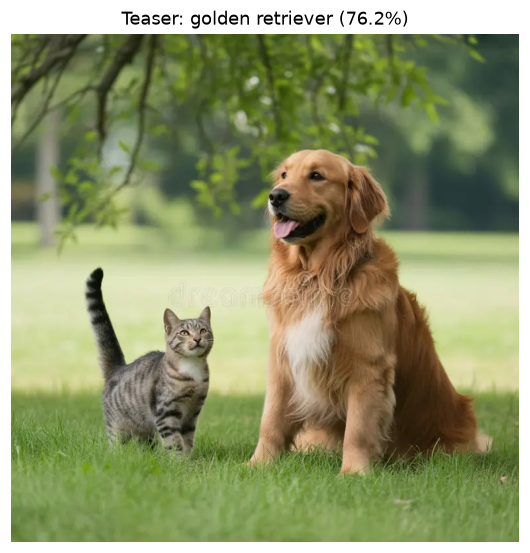

Top-3 predições ImageNet:
  golden retriever: 0.762
  tennis ball: 0.031
  Labrador retriever: 0.014


In [2]:
base_dir = os.path.abspath('.')
img_path = "assets/cat_dog.jpg" if os.path.isdir("assets") and os.path.exists("assets/cat_dog.jpg") else "notebooks/assets/cat_dog.jpg"

img = Image.open(img_path).convert("RGB")
x = preprocess(img)
model = load_model("vgg16", device=env['device'])
idx, p = predict(model, x, topk=3)

fig, ax = plt.subplots(figsize=(6, 6), dpi=110)
ax.imshow(img)
ax.axis("off")
top1_name = labels[int(idx[0])]
top1_prob = float(p[0])
ax.set_title(f"Teaser: {top1_name} ({top1_prob:.1%})")
plt.show()

print(f"Top-3 predições ImageNet:")
for i, prob in zip(idx, p):
    print(f"  {labels[int(i)]}: {float(prob):.3f}")